In [ ]:

# =========================
# 1) INSTALL DEPENDENCIES
# =========================
# We pin TensorFlow and TensorFlow-Text to matching versions (2.19)
# to avoid the common conflict where TF is 2.20+ but tf-text/tf-keras expect 2.19.
# SentencePiece is used by many tokenizers (e.g., T5).

!pip -q install -U "tensorflow==2.19.0" "tensorflow-text==2.19.0" transformers sentencepiece

# (Optional) If you know you'll never use PyTorch here, you can ignore it.
# Transformers supports multiple backends; we're using TensorFlow.


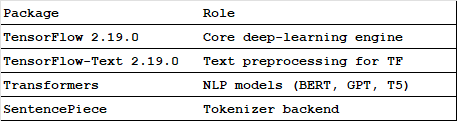

In [ ]:

# =========================
# 2) VERIFY INSTALL
# =========================
# This helps ensure the environment is consistent before we proceed.

import tensorflow as tf, transformers, tensorflow_text as tf_text
print("TensorFlow:", tf.__version__)
print("Transformers:", transformers.__version__)
print("TF-Text available:", tf_text.__name__)


TensorFlow: 2.19.0
Transformers: 4.57.3
TF-Text available: tensorflow_text


*******************************
**import tensorflow as tf**

Loads the TensorFlow library — the deep learning framework that actually performs all the neural network operations (training/inference).

*******************************

**transformers**

Loads the Hugging Face Transformers library.

This contains pre-trained models (BERT, GPT, T5, etc.)

*******************************
**tensorflow_text as tf_text**

Loads the TensorFlow Text library — adds specialized text preprocessing layers and operations that integrate smoothly with TensorFlow.

It must match your TensorFlow version (2.19.0).


## Sentiment Analysis (Encoder-only: DistilBERT)

We will use `distilbert-base-uncased-finetuned-sst-2-english`.  
Some Hub models ship **only PyTorch weights**. To ensure TensorFlow loading, we set **`from_pt=True`** which converts weights on-the-fly.


In [ ]:

# -------------------------------
# SENTIMENT ANALYSIS — FULLY COMMENTED
# -------------------------------
# Step 1: Import tokenizer + TF model class + pipeline
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification, pipeline
import tensorflow as tf




🧠 Explanation:

**AutoTokenizer:** Automatically selects the right tokenizer for the chosen model (here, DistilBERT).
It converts text into token IDs that the model can understand.

**TFAutoModelForSequenceClassification:** Loads a TensorFlow version of a pre-trained classification model (used for sentiment tasks).

**pipeline:** High-level API from Hugging Face that wraps the whole process (tokenization → model → decoding results).

**tensorflow as tf:** Imports TensorFlow, your backend deep-learning engine.

In [ ]:
# Step 2: Set a seed to keep results reproducible in class demos
tf.random.set_seed(42)

# Step 3: Pick a compact, classroom-friendly model
model_id = "distilbert-base-uncased-finetuned-sst-2-english"


📦 Meaning:
This string identifies the model from the Hugging Face Hub.

**distilbert-base-uncased →** a smaller, faster version of BERT.

**finetuned-sst-2-english →** fine-tuned on the SST-2 dataset (Stanford Sentiment Treebank).
✅ **It predicts positive or negative sentiment.**

In [ ]:
# Step 4: Load tokenizer (always framework-agnostic)
tok = AutoTokenizer.from_pretrained(model_id)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

**🔠 What happens:**
Downloads and loads the tokenizer configuration for this model.
It handles:



*   Breaking text into tokens (subwords)
*   Adding special tokens like [CLS] and [SEP]





Converting tokens ↔ IDs
⚙️ Works with both PyTorch and TensorFlow.

In [ ]:
# Step 5: Load the model.
# If TF weights are not available for this model, `from_pt=True` converts PyTorch weights to TF automatically.
tf_model = TFAutoModelForSequenceClassification.from_pretrained(
    model_id,
    from_pt=True  # <-- crucial when TF weights are missing
)

pytorch_model.bin:   0%|          | 0.00/268M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All PyTorch model weights were used when initializing TFDistilBertForSequenceClassification.

All the weights of TFDistilBertForSequenceClassification were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFDistilBertForSequenceClassification for predictions without further training.


**⚙️ What this does:**








*   Downloads the pre-trained model weights from the Hugging Face Hub.
*   Loads it as a TensorFlow model.
*   If the model only has PyTorch weights, the argument from_pt=True automatically converts them to TensorFlow format.




In [ ]:
# Step 6: Build a pipeline that wraps tokenization + model + postprocessing
sentiment = pipeline(
    "sentiment-analysis",
    model=tf_model,       # explicit TF model object
    tokenizer=tok,
    framework="tf"        # tell pipeline to use TensorFlow backend
)

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Device set to use 0


**🚀 Purpose:**
Creates a ready-to-use **sentiment analysis pipeline.**
This wraps:

*   Tokenization (handled by tok)
*   Forward pass through the model (tf_model)
*   Decoding prediction outputs (into labels like “POSITIVE” or “NEGATIVE”)


framework="tf" ensures TensorFlow (not PyTorch) is used for computation.


### ✅ Exercises: Sentiment
1. Enter **three** custom sentences: one positive, one negative, one ambiguous.  
2. Observe how confidence scores change when you rephrase.


In [ ]:
# Step 7: Test on a few sentences
samples = [
    "The movie was surprisingly good!",
    "I am not happy with this product.",
    "It's okay, comparing with other brands this is just fine"
]
for s in samples:
    print(s, "->", sentiment(s)[0])

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


The movie was surprisingly good! -> {'label': 'POSITIVE', 'score': 0.9998613595962524}
I am not happy with this product. -> {'label': 'NEGATIVE', 'score': 0.999772846698761}
It's okay, comparing with other brands this is just fine -> {'label': 'POSITIVE', 'score': 0.9998182654380798}


In [ ]:
sentiment("The boy is crying for an icecream which is been stolen by his friend")

[{'label': 'NEGATIVE', 'score': 0.9945388436317444}]

In [ ]:
sentiment("Congratulations!!!")

[{'label': 'POSITIVE', 'score': 0.9996906518936157}]